# Senzai et al. (2019) recording YMV15: what is in the data?

Single-unit recordings from mouse visual cortex during natural sleep and wakefulness (Senzai, Fernandez-Ruiz & Buzsáki, *Neuron* 2019), shipped with Sooter's prox_crit_toolkit demo. Not own data.

This notebook does three things:
- shows what the `.mat` file contains, and why printing it shows only part of it;
- turns it into readable tables (`src/utils/senzai2019.py`);
- exports them as CSV to `data/processed/`.

In [1]:
%load_ext jupyter_black

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

from src.analysis.prox_crit import get_spike_counts
from src.config.paths import YMV15_MAT, FIGURES_DIR
from src.utils.senzai2019 import load_ymv15, export_ymv15_csv

## 1. The raw `.mat` file

`scipy.io.loadmat` returns a Python `dict`: one entry per MATLAB variable, plus three bookkeeping entries (`__header__`, `__version__`, `__globals__`). Without `squeeze_me=True`, every MATLAB vector arrives as a 2-D array of shape (1, N).

In [2]:
raw = sio.loadmat(YMV15_MAT)
print(f"file: {YMV15_MAT.name}, {YMV15_MAT.stat().st_size / 1e6:.1f} MB")
print(f"{len(raw)} entries in the dict:\n")
for key, value in raw.items():
    if isinstance(value, np.ndarray):
        print(
            f"  {key:12s} numpy array, shape {str(value.shape):14s} dtype {str(value.dtype):8s} first values: {value.ravel()[:4]}"
        )
    else:
        print(f"  {key:12s} {type(value).__name__:6s} {value!r}")

file: senzai2019_YMV15.mat, 94.2 MB
9 entries in the dict:

  __header__   bytes  b'MATLAB 5.0 MAT-file Platform: nt, Created on: Mon Mar 13 11:35:56 2023'
  __version__  str    '1.0'
  __globals__  list   []
  Session      numpy array, shape (1,)           dtype <U5      first values: ['YMV15']
  NREM         numpy array, shape (52, 2)        dtype int64    first values: [1555 1889 1930 2303]
  REM          numpy array, shape (15, 2)        dtype int64    first values: [2807 2930 3378 3419]
  WAKE         numpy array, shape (5, 2)         dtype int64    first values: [   2  746 1289 1554]
  st           numpy array, shape (1, 7850337)   dtype float64  first values: [0.00445 0.00455 0.00525 0.0074 ]
  clu          numpy array, shape (1, 7850337)   dtype int32    first values: [53 37 48 61]


### Why `data` (or `st`) shows only part of the content

The arrays have 7.85 million elements. When an array has more than `threshold` elements (default 1000), numpy prints only the first and last 3 values with `...` in between. The data are all there; only the *printout* is summarized. Printing everything would mean millions of lines.

Better ways to look at big data:
- slice it (`st[:20]`, `st[1000:1010]`);
- summarize it (`describe()`, histograms);
- put it in a pandas `DataFrame` and open it in VS Code's *Data Viewer* (Jupyter variables panel → the table icon next to the variable);
- open the exported CSV (section 4).

In [3]:
st = raw["st"].ravel()
print(
    f"numpy print threshold: {np.get_printoptions()['threshold']} elements; st has {st.size:,}"
)
print("\nprinting st (summarized):")
print(st)
print("\nfirst 20 spike times (s):")
print(st[:20])

numpy print threshold: 1000 elements; st has 7,850,337

printing st (summarized):
[4.45000000e-03 4.55000000e-03 5.25000000e-03 ... 2.24419605e+04
 2.24419621e+04 2.24419647e+04]

first 20 spike times (s):
[0.00445 0.00455 0.00525 0.0074  0.0078  0.0092  0.01045 0.0115  0.022
 0.0246  0.02515 0.0272  0.02755 0.02855 0.03265 0.03435 0.03565 0.0415
 0.0417  0.0458 ]


## 2. As tables

In [4]:
spikes, states = load_ymv15()
print(
    f"spikes: DataFrame with {len(spikes):,} rows (one per spike) and columns {list(spikes.columns)}"
)
print(spikes.dtypes.to_string(), "\n")
print("first rows:")
print(spikes.head(8).to_string())
print("\nlast rows:")
print(spikes.tail(3).to_string())
print(f"\nsorted by time: {spikes['time_s'].is_monotonic_increasing}")
print(
    f"recording spans {spikes['time_s'].min():.5f} s to {spikes['time_s'].max():.5f} s ({spikes['time_s'].max() / 3600:.2f} h)"
)
print(
    f"spike times lie on a {1 / 20000 * 1000:.2f} ms grid (20 kHz sampling): {np.allclose(np.round(spikes['time_s'] * 20000), spikes['time_s'] * 20000)}"
)

spikes: DataFrame with 7,850,337 rows (one per spike) and columns ['time_s', 'unit']
time_s    float64
unit        int32 

first rows:
    time_s  unit
0  0.00445    53
1  0.00455    37
2  0.00525    48
3  0.00740    61
4  0.00780    36
5  0.00920    58
6  0.01045    55
7  0.01150    61

last rows:
              time_s  unit
7850334  22441.96050    40
7850335  22441.96215    58
7850336  22441.96475    45

sorted by time: True
recording spans 0.00445 s to 22441.96475 s (6.23 h)
spike times lie on a 0.05 ms grid (20 kHz sampling): True


### Units (neurons)

In [5]:
duration = spikes["time_s"].max() - spikes["time_s"].min()
per_unit = spikes.groupby("unit").agg(
    n_spikes=("time_s", "size"),
    first_spike_s=("time_s", "min"),
    last_spike_s=("time_s", "max"),
)
per_unit["rate_hz"] = per_unit["n_spikes"] / duration
print(
    f"{len(per_unit)} units, ids {per_unit.index.min()}..{per_unit.index.max()} (not contiguous)"
)
print(
    f"firing rates: median {per_unit['rate_hz'].median():.2f} Hz, range {per_unit['rate_hz'].min():.3f}-{per_unit['rate_hz'].max():.1f} Hz"
)
print(f"population rate: {len(spikes) / duration:.0f} spikes/s in total\n")
print("units sorted by rate (top 10):")
print(per_unit.sort_values("rate_hz", ascending=False).head(10).round(2).to_string())

72 units, ids 2..80 (not contiguous)
firing rates: median 2.90 Hz, range 0.110-45.7 Hz
population rate: 350 spikes/s in total

units sorted by rate (top 10):
      n_spikes  first_spike_s  last_spike_s  rate_hz
unit                                                
55     1026299           0.01      22441.95    45.73
45      789753           1.08      22441.96    35.19
47      726633           0.03      22441.95    32.38
53      323202           0.00      22441.96    14.40
18      310847           2.14      22441.95    13.85
48      282589           0.01      22441.91    12.59
17      266800           0.76      22441.93    11.89
42      218571           0.16      22441.95     9.74
5       196777           0.02      22441.91     8.77
40      183501           0.03      22441.96     8.18


### Behavioral states

Each row is one episode. Start and end are whole seconds; parts of the recording belong to no state.

In [6]:
with pd.option_context("display.max_rows", 100):
    print(states.to_string())
summary = states.groupby("state")["duration_s"].agg(
    episodes="size", total_s="sum", median_s="median", min_s="min", max_s="max"
)
print("\nper state:")
print(summary.to_string())
covered = states["duration_s"].sum()
print(
    f"\nstates cover {covered:.0f} s of {duration:.0f} s recording ({covered / duration:.0%}); the rest is unlabeled"
)

   state  start_s    end_s  duration_s
0   WAKE      2.0    746.0       744.0
1   WAKE   1289.0   1554.0       265.0
2   NREM   1555.0   1889.0       334.0
3   NREM   1930.0   2303.0       373.0
4   NREM   2440.0   2790.0       350.0
5    REM   2807.0   2930.0       123.0
6   NREM   2947.0   3354.0       407.0
7    REM   3378.0   3419.0        41.0
8   NREM   3792.0   3849.0        57.0
9   NREM   3858.0   4180.0       322.0
10   REM   4230.0   4231.0         1.0
11  NREM   4232.0   4414.0       182.0
12   REM   4442.0   4538.0        96.0
13  NREM   4562.0   5095.0       533.0
14   REM   5130.0   5227.0        97.0
15  NREM   5228.0   5335.0       107.0
16  NREM   5360.0   5660.0       300.0
17  NREM   5686.0   5827.0       141.0
18  NREM   5905.0   5993.0        88.0
19  WAKE   5994.0   7036.0      1042.0
20  NREM   7037.0   7308.0       271.0
21  NREM   7340.0   7450.0       110.0
22  NREM   7492.0   7812.0       320.0
23  NREM   7840.0   7921.0        81.0
24  NREM   7980.0   8136.

## 3. From spikes to the time series that $d_2$ is computed on

The tutorial bins all spikes (all units pooled) into 40 ms bins. This gives the population spike count per bin, the time series that `calc_db` fits the AR model to.

In [7]:
delta_t = 0.04
x = get_spike_counts(
    spikes["time_s"].to_numpy(), spikes["time_s"].min(), spikes["time_s"].max(), delta_t
)
print(
    f"population spike-count series: {x.size:,} bins of {delta_t * 1000:.0f} ms, dtype {x.dtype}"
)
print(
    f"counts per bin: mean {x.mean():.1f}, std {x.std():.1f}, min {x.min():.0f}, max {x.max():.0f}, zeros {np.mean(x == 0):.2%}"
)
print(f"first 20 bins: {x[:20].astype(int)}")
mean_isi = np.mean(np.diff(spikes["time_s"]))
print(
    f"\nmean population inter-spike interval {mean_isi * 1000:.2f} ms vs bin {delta_t * 1000:.0f} ms (tutorial tip: bin >= mean ISI)"
)

population spike-count series: 561,049 bins of 40 ms, dtype float64
counts per bin: mean 14.0, std 10.0, min 0, max 70, zeros 10.98%
first 20 bins: [19  9 13 14 14  8 11 14 10 10 14 10 10 17 17 11 13 14 16 13]

mean population inter-spike interval 2.86 ms vs bin 40 ms (tutorial tip: bin >= mean ISI)


Where do the empty bins come from? There are no gaps > 1 s in the recording, so they are scattered. Splitting by state shows they are concentrated in NREM sleep, consistent with cortical DOWN states (brief population silences during slow-wave sleep).

In [8]:
for state in ("WAKE", "NREM", "REM"):
    episodes = states.loc[states["state"] == state, ["start_s", "end_s"]].to_numpy()
    counts = np.concatenate(
        [
            get_spike_counts(spikes["time_s"].to_numpy(), start, end, delta_t)
            for start, end in episodes
        ]
    )
    print(
        f"{state:4s}: {counts.size:7,} bins, mean {counts.mean():5.1f} spikes/bin, empty bins {np.mean(counts == 0):6.1%}"
    )

WAKE:  81,450 bins, mean  16.6 spikes/bin, empty bins   3.8%
NREM: 271,475 bins, mean  11.8 spikes/bin, empty bins  15.8%
REM :  30,600 bins, mean  17.8 spikes/bin, empty bins   1.7%


2,798 spikes from 70 units in 3000-3010 s


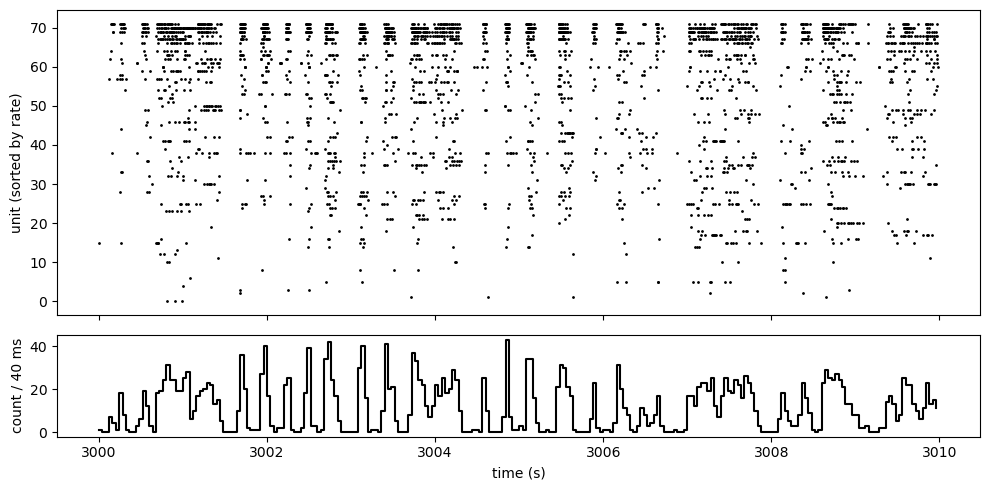

In [9]:
t0, t1 = 3000, 3010  # a 10 s window
window = spikes[(spikes["time_s"] >= t0) & (spikes["time_s"] < t1)]
order_by_rate = {u: i for i, u in enumerate(per_unit.sort_values("rate_hz").index)}

fig, (ax_raster, ax_counts) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
ax_raster.scatter(window["time_s"], window["unit"].map(order_by_rate), s=1, color="k")
ax_raster.set_ylabel("unit (sorted by rate)")
counts_window = get_spike_counts(window["time_s"].to_numpy(), t0, t1, delta_t)
ax_counts.step(
    t0 + delta_t * np.arange(counts_window.size), counts_window, where="post", color="k"
)
ax_counts.set_xlabel("time (s)")
ax_counts.set_ylabel("count / 40 ms")
fig.tight_layout()
# fig.savefig(FIGURES_DIR / "senzai2019_raster.png", dpi=150, bbox_inches="tight")
print(f"{len(window):,} spikes from {window['unit'].nunique()} units in {t0}-{t1} s")

## 4. Export as CSV

- `data/processed/senzai2019_YMV15_spikes.csv`: ~125 MB, one row per spike (`time_s,unit`). It is git-ignored because it exceeds GitHub's 100 MB file limit and can always be regenerated with this cell.
- `data/processed/senzai2019_YMV15_states.csv`: 72 rows.

In [10]:
spikes_path, states_path = export_ymv15_csv()
for path in (spikes_path, states_path):
    with open(path) as f:
        head = [next(f).rstrip() for _ in range(4)]
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB; first lines:")
    print("   " + "\n   ".join(head))

senzai2019_YMV15_spikes.csv: 121.3 MB; first lines:
   time_s,unit
   0.00445,53
   0.00455,37
   0.00525,48
senzai2019_YMV15_states.csv: 0.0 MB; first lines:
   state,start_s,end_s,duration_s
   WAKE,2.0,746.0,744.0
   WAKE,1289.0,1554.0,265.0
   NREM,1555.0,1889.0,334.0
